<a href="https://colab.research.google.com/github/kavipriya-ui/Amazon-E-commerce-Analysis/blob/main/amazon_e_commerce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("/content/amazon_orders.csv")
products = pd.read_csv("/content/amazon_products.csv")
print(orders.shape, products.shape)
orders.info()
orders.isnull().sum()

(7967, 12) (120, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7967 entries, 0 to 7966
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        7967 non-null   object 
 1   order_date      7967 non-null   object 
 2   customer_id     7967 non-null   object 
 3   product_id      7967 non-null   object 
 4   category        7967 non-null   object 
 5   quantity        7967 non-null   int64  
 6   amount          7847 non-null   float64
 7   status          7967 non-null   object 
 8   payment_method  7886 non-null   object 
 9   ship_state      7967 non-null   object 
 10  ship_city       7967 non-null   object 
 11  delivery_days   6812 non-null   float64
dtypes: float64(2), int64(1), object(9)
memory usage: 747.0+ KB


,0
order_id,0
order_date,0
customer_id,0
product_id,0
category,0
quantity,0
amount,120
status,0
payment_method,81
ship_state,0


In [3]:
print(orders.duplicated().sum())   # 40
orders = orders.drop_duplicates()

40


In [11]:
orders["ship_state"] = orders["ship_state"].str.strip().str.title()
orders["order_date"] = pd.to_datetime(orders["order_date"], dayfirst=True)
orders["month"] = orders["order_date"].dt.to_period("M").astype(str)

print(orders["ship_state"].nunique())
orders.head()

10


,order_id,order_date,customer_id,product_id,category,quantity,amount,status,payment_method,ship_state,ship_city,delivery_days,month
0,AMZ-100273,2025-09-14,C01089,P0008,Electronics,2,7781.20,Delivered,Credit Card,Maharashtra,Mumbai,5.0,2025-09
1,AMZ-102746,2025-06-13,C00044,P0032,Fashion,1,408.80,Delivered,Cash on Delivery,Maharashtra,Pune,2.0,2025-06
2,AMZ-106992,2025-06-01,C03245,P0014,Electronics,1,3437.40,Delivered,Debit Card,Karnataka,Mysuru,3.0,2025-06
3,AMZ-100460,2025-09-03,C02183,P0113,Grocery,1,579.60,Pending,UPI,West Bengal,Kolkata,NaN,2025-09
4,AMZ-105810,2025-07-29,C00687,P0009,Electronics,1,3848.45,Delivered,Cash on Delivery,West Bengal,Kolkata,6.0,2025-07


In [14]:
valid["amount"] = valid["amount"].fillna(0)

valid["payment_method"] = valid["payment_method"].fillna("Unknown")

valid["delivery_days"] = valid["delivery_days"].fillna(
    valid["delivery_days"].median()
)

In [5]:
orders["payment_method"] = orders["payment_method"].fillna("Unknown")

orders = orders.merge(products[["product_id","brand","rating","discount_pct","mrp"]],
                      on="product_id", how="left")
orders["amount"] = orders["amount"].fillna(
    orders["mrp"] * (1 - orders["discount_pct"]/100) * orders["quantity"]).round(2)

In [7]:
valid = orders[orders["status"] != "Cancelled"]
total_sales = valid["amount"].sum()
total_orders = orders["order_id"].nunique()
aov = total_sales / valid["order_id"].nunique()
cancel_rate = (orders["status"] == "Cancelled").mean() * 100
return_rate = (orders["status"] == "Returned").mean() * 100
print(round(total_sales), total_orders, round(aov, 2), round(cancel_rate, 2), round(return_rate, 2))

15128884 7927 2136.55 10.67 7.32


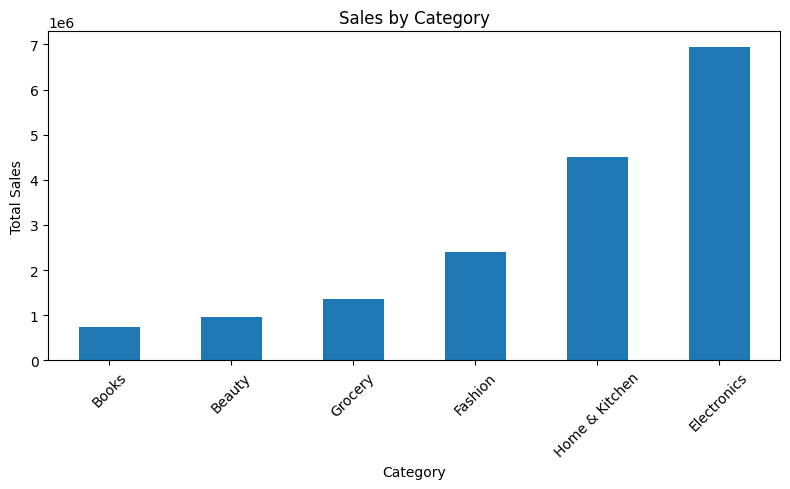

In [18]:
category_sales = orders.groupby("category")["amount"].sum()

category_sales.sort_values().plot(
    kind="bar",
    figsize=(8,5),
    title="Sales by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

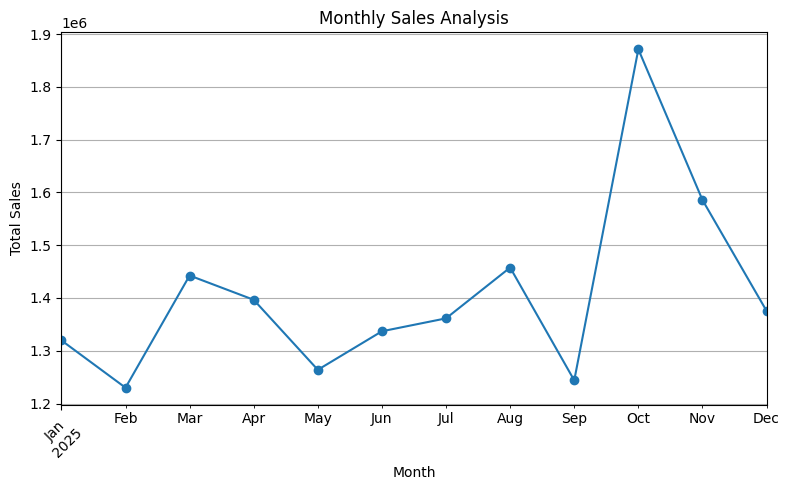

In [20]:
orders["month"] = orders["order_date"].dt.to_period("M")

monthly_sales = orders.groupby("month")["amount"].sum()

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(8,5),
    title="Monthly Sales Analysis"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

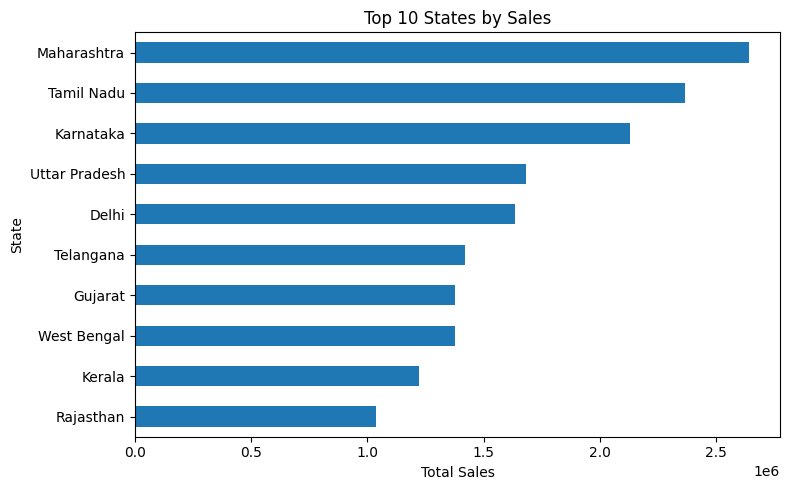

In [21]:
state_sales = orders.groupby("ship_state")["amount"].sum()

state_sales.nlargest(10).sort_values().plot(
    kind="barh",
    figsize=(8,5),
    title="Top 10 States by Sales"
)

plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()

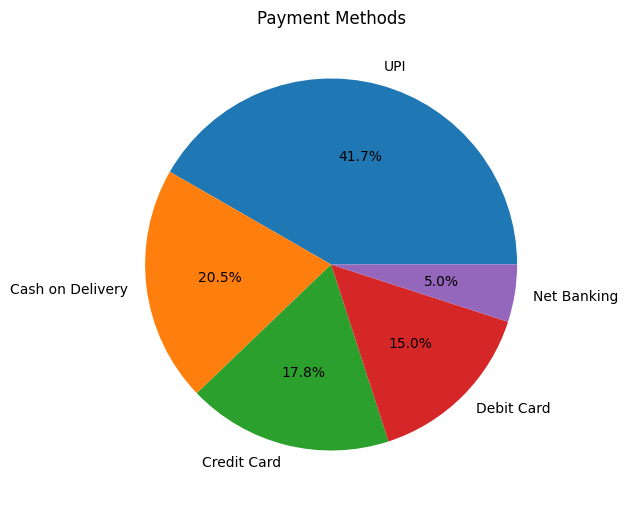

In [23]:
payment = orders["payment_method"].value_counts()

payment.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6,7),
    title="Payment Methods"
)

plt.ylabel("")
plt.show()

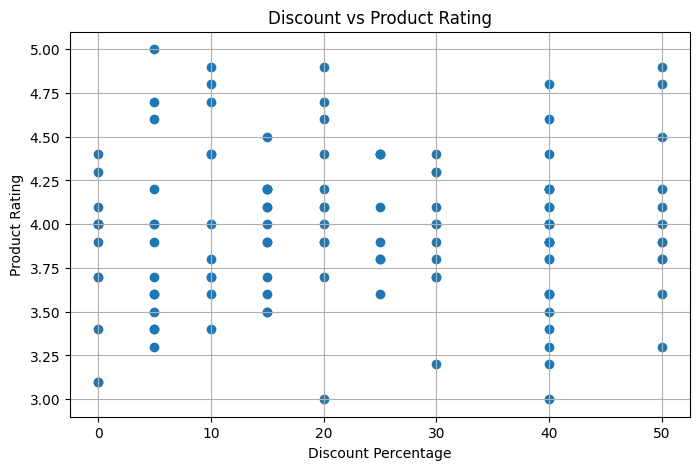

In [24]:
plt.figure(figsize=(8,5))

plt.scatter(
    products["discount_pct"],
    products["rating"]
)

plt.title("Discount vs Product Rating")
plt.xlabel("Discount Percentage")
plt.ylabel("Product Rating")

plt.grid()
plt.show()